딥러닝 파이토치 교과서
ch7. 5 (pg.393~417)

# 7.5 LSTM

### 7.5.1 LSTM구조

- 망각 게이트

: 과거 정보를 어느 정도 기억할지 결정한다.
과거 정보와 현재 데이터를 입력받아 시그모이드를 취한 후 그 값을 과거 정보에 곱해준다. 따라서 시그모이드의 출력이 0이면 과거 정보는 버리고, 1이면 과거 정보는 온전히 보존한다.

망각 게이트 수식
$$f_t = \sigma(w_f [h_{t-1}, x_t])$$$$c_t = f_t \cdot c_{t-1}$$

$ x_t$은 새로운 입력 값이고, $h_{t-1}$은 이전 은닉층에서 입력되는 값이다.

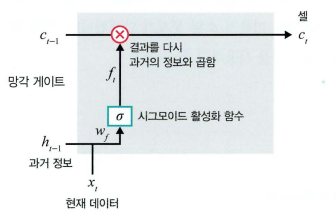

- 입력 게이트

현재 정보를 기억하기 위해 만들어짐. 과거 정보와 현재 데이터를 입력받아 시그모이드와 하이퍼볼릭 탄젠트 함수를 기반으로 현재 정보에 대한 보존량을 결정한다.

1. 계산한 값이 1이면 입력 $ x_t$가 들어올 수 있도록 허용
2. 계산한 값이 0이면 차단

입력 게이트 수식

$$i_t = \sigma(w_i [h_{t-1}, x_t])$$$$\tilde{c}_t = \tanh(w_c [h_{t-1}, x_t])$$$$c_t = c_{t-1} + i_t \cdot \tilde{c}_t$$

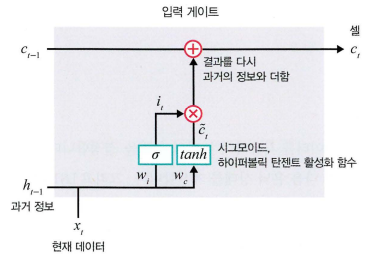

- 셀

; 각 단계에 대한 은닉, 노드를 메모리 셀이라고 한다. 총합을 사용하여 셀 값을 반영하며, 이것으로 기울기 소멸 문제가 해결된다.

- 출력 게이트

: 과거 정보와 현재 데이터를 사용하여 뉴런의 출력을 결정한다. 이전 은닉상태와 $t$번째 입력을 고려하여 다음 은닉 상태를 계산한다.

LSTM에서는 이 은닉 상태가 그 시점에서의 출력이 됨


1. 계산한 값이 1이면 의미 있는 결과로 최종 출력
2. 계산한 값이 0이면 해당 연산 출력을 하지 않음

출력 게이트 수식:

$$o_t = σ(w_o[h_{t-1}, x_t])
$$$$h_t = o_t \cdot \ tanh(c_{t-1})$$

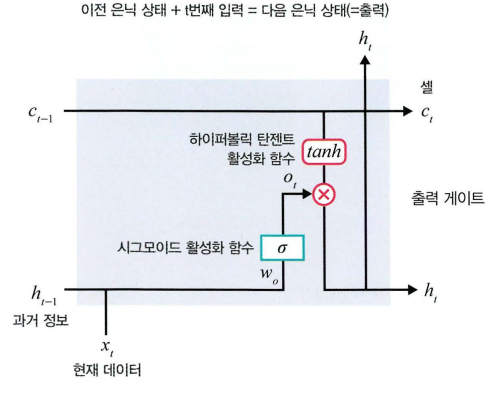

#### LSTM 전체 게이트

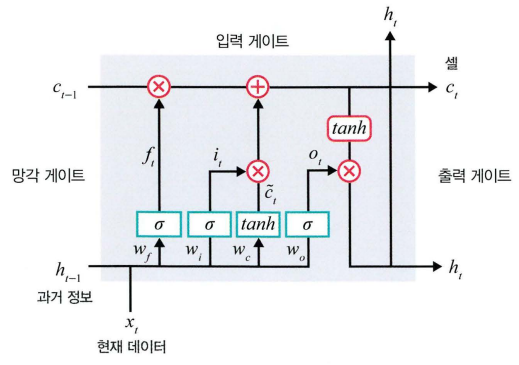

- **LSTM역전파**

셀을 통해 역전파를 수행하기 때문에 '중단 없는 기울기'라고도 한다.

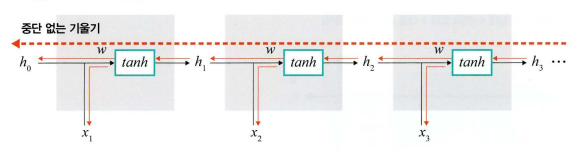

**역전파 수행 공식**
$$ t_t = tanh(w_{hh}h_{t-1}+w_{xh}x_t)$$
$$= \tanh\left( \begin{pmatrix} w_{hh} & w_{xh} \end{pmatrix} \begin{pmatrix} h_{t-1} \\ x_t \end{pmatrix} \right)$$$$= \tanh\left( w \begin{pmatrix} h_{t-1} \\ x_t \end{pmatrix} \right)$$

## LSTM 셀 구현

In [11]:
import torch
import torch.nn as nn
import torchvision.transforms as transforms
import torchvision.datasets as dataset
from torch.nn import Parameter
from torch import Tensor
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torch.autograd import Variable # Variable 임포트 추가
import math


device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
cuda = True if torch.cuda.is_available() else False

Tensor = torch.cuda.FloatTensor if cuda else torch.FloatTensor #GPU사용에 필요

torch.manual_seed(125)
if torch.cuda.is_available():
  torch.cuda.manual_seed_all(125)

In [2]:
import torchvision.transforms as transforms

mnist_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,),(1.0))   #평균을 0.5, 표준편차는 1.0으로 데이터 정규화
])

In [3]:
!git clone https://github.com/gilbutITbook/080289.git

fatal: destination path '080289' already exists and is not an empty directory.


In [4]:
from torchvision.datasets import MNIST

download_root = '/content/080289/chap07/data/MNIST_DATASET'

train_dataset = MNIST(download_root, transform=mnist_transform, train=True, download=True)
valid_dataset = MNIST(download_root, transform=mnist_transform, train=False, download=True)
test_dataset = MNIST(download_root, transform=mnist_transform, train=False, download=True)

In [5]:
batch_size = 64
train_loader = DataLoader(dataset=train_dataset, batch_size=batch_size, shuffle=True)
valid_loader = DataLoader(dataset=valid_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(dataset=test_dataset, batch_size=batch_size, shuffle=True)

In [6]:
#배치 크기 및 에포크 등 변수에 대한 값 지정
batch_size = 100
n_iters=6000
num_epochs = n_iters/(len(train_dataset)/batch_size)
num_epochs = int(num_epochs)

In [7]:
# LSTM 셀 네트워크 구축

class LSTMCell(nn.Module):
  def __init__(self, input_size, hidden_size, bias=True):
    super(LSTMCell, self).__init__()
    self.input_size = input_size
    self.hidden_size=hidden_size
    self.bias = bias
    self.x2h = nn.Linear(input_size,4*hidden_size, bias=bias)
    self.h2h = nn.Linear(hidden_size,4*hidden_size, bias=bias)
    self.reset_parameters()

  def reset_parameters(self):
    std = 1.0/math.sqrt(self.hidden_size)
    for w in self.parameters():
      w.data.uniform_(-std, std)

  def forward(self, x, hidden):
    hx, cx = hidden
    x = x.view(-1, x.size(1))

    gates = self.x2h(x)+self.h2h(hx)
    gates = gates.squeeze()
    ingate, forgetgate, cellgate, outgate = gates.chunk(4,1)

    ingate = F.sigmoid(ingate)
    forgetgate = F.sigmoid(forgetgate)
    cellgate = F.tanh(cellgate)
    outgate = F.sigmoid(outgate)

    cy = torch.mul(cx, forgetgate)+torch.mul(ingate, cellgate)
    hy = torch.mul(outgate, F.tanh(cy))
    return(hy, cy)

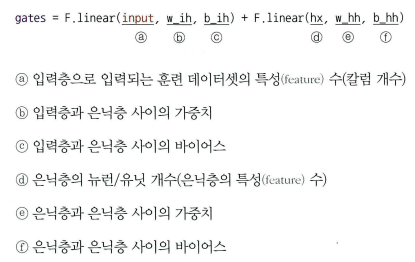

In [12]:
class LSTMModel(nn.Module):
  def __init__(self, input_dim, hidden_dim, layer_dim, output_dim, bias=True):
    super(LSTMModel, self).__init__()
    self.hidden_dim = hidden_dim

    self.layer_dim = layer_dim
    self.lstm = LSTMCell(input_dim, hidden_dim, layer_dim)
    self.fc = nn.Linear(hidden_dim, output_dim)

  def forward(self, x):
    if torch.cuda.is_available(): #GPU 사용 유무 확인
      h0 = Variable(torch.zeros(self.layer_dim, x.size(0), self.hidden_dim).cuda())
    else:
      h0 = Variable(torch.zeros(self.layer_dim, x.size(0), self.hidden_dim))

    if torch.cuda.is_available():
      c0 = Variable(torch.zeros(self.layer_dim, x.size(0), self.hidden_dim).cuda())
    else:
      c0 = Variable(torch.zeros(self.layer_dim, x.size(0), hidden_dim))

    outs = []
    cn = c0[0,:,:]
    hn = h0[0,:,:]

    for seq in range(x.size(1)):
      hn.cn = self.lstm(x[:, seq,:], (hn, cn))
      outs.append(hn)

    out = outs[-1].squeeze()
    out = self.fc(out)
    return out

In [13]:
input_dim = 28
hidden_dim = 128
layer_dim = 1
output_dim = 10

model = LSTMModel(input_dim, hidden_dim, layer_dim, output_dim)
if torch.cuda.is_available():
  model.cuda()
criterion = nn.CrossEntropyLoss()
learning_rate=0.1
optimizer = torch.optim.SGD(model.parameters(), lr =learning_rate)

In [14]:
seq_dim = 28
loss_list = []
iter = 0

for epoch in range(num_epochs):
    for i, (images, labels) in enumerate(train_loader):  # 훈련 데이터셋을 이용한 모델 학습
        if torch.cuda.is_available():  # GPU 사용 유무 확인
            images = Variable(images.view(-1, seq_dim, input_dim).cuda())  # ①
            labels = Variable(labels.cuda())
        else:  # GPU를 사용하지 않기 때문에 else 구문이 실행
            images = Variable(images.view(-1, seq_dim, input_dim))
            labels = Variable(labels)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)  # 손실 함수를 이용하여 오차 계산

        if torch.cuda.is_available():
            loss.cuda()

        loss.backward()
        optimizer.step()  # 파라미터 업데이트
        loss_list.append(loss.item())
        iter += 1

        if iter % 500 == 0:  # 정확도(accuracy) 계산
            correct = 0
            total = 0
            for images, labels in valid_loader:  # 검증 데이터셋을 이용한 모델 성능 검증
                if torch.cuda.is_available():
                    images = Variable(images.view(-1, seq_dim, input_dim).cuda())
                else:
                    images = Variable(images.view(-1, seq_dim, input_dim))

                outputs = model(images)
                _, predicted = torch.max(outputs.data, 1)  # 모델을 통과한 결과의 최댓값으로부터 예측 결과 가져오기

                total += labels.size(0)  # 총 레이블 수
                if torch.cuda.is_available():
                    correct += (predicted.cpu() == labels.cpu()).sum()
                else:
                    correct += (predicted == labels).sum()

            accuracy = 100 * correct / total
            print('Iteration: {}. Loss: {}. Accuracy: {}'.format(iter, loss.item(), accuracy))

Iteration: 500. Loss: 2.2934885025024414. Accuracy: 11.350000381469727
Iteration: 1000. Loss: 2.304047107696533. Accuracy: 11.350000381469727
Iteration: 1500. Loss: 2.305588722229004. Accuracy: 11.350000381469727
Iteration: 2000. Loss: 2.304029941558838. Accuracy: 11.350000381469727
Iteration: 2500. Loss: 2.3115272521972656. Accuracy: 11.350000381469727
Iteration: 3000. Loss: 2.3076298236846924. Accuracy: 11.350000381469727
Iteration: 3500. Loss: 2.2945728302001953. Accuracy: 11.350000381469727
Iteration: 4000. Loss: 2.2909703254699707. Accuracy: 11.350000381469727
Iteration: 4500. Loss: 2.3079047203063965. Accuracy: 11.350000381469727
Iteration: 5000. Loss: 2.2850403785705566. Accuracy: 11.350000381469727
Iteration: 5500. Loss: 2.2929563522338867. Accuracy: 11.350000381469727
Iteration: 6000. Loss: 2.299772262573242. Accuracy: 11.350000381469727
Iteration: 6500. Loss: 2.302269458770752. Accuracy: 11.350000381469727
Iteration: 7000. Loss: 2.293032169342041. Accuracy: 11.350000381469727

In [19]:
def evaluate(model, val_iter):
  corrects, total, total_loss = 0,0,0
  model.eval()
  for images, labels in val_iter:
    if torch.cuda.is_available():
      images = Variable(images.view(-1,seq_dim, input_dim).cuda())
      labels = labels.cuda()
    else:
      images = Variable(images.view(-1,seq_dim, input_dim)).to(device)
      labels = labels.to(device)


    logit = model(images).to(device)
    loss = F.cross_entropy(logit, labels, reduction='sum')
    _, predicted = torch.max(logit.data,1)
    total += labels.size(0)
    total_loss += loss.item()
    corrects += (predicted == labels).sum()

  avg_loss = total_loss / len(val_iter.dataset)
  avg_accuracy = corrects/ total
  return avg_loss, avg_accuracy

In [20]:
test_loss, test_acc = evaluate(model, test_loader)
print('Test Loss: %5.2f | Test Accuracy: %5.2f' % (test_loss, test_acc))

Test Loss:  2.30 | Test Accuracy:  0.11


## 7.5.3 LSTM 계층 구현

**스타벅스 주가 데이터셋 사용하여 모델이 얼마나 주가 예측을 잘 하는가 알아보기**

In [23]:
import os
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from torch.autograd import Variable
from tqdm import tqdm_notebook
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split

# 'cpu) 오타를 'cpu')로 수정하였습니다.
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

In [25]:
data = pd.read_csv('/content/080289/chap07/data/SBUX.csv')
print(data.dtypes)

Date          object
Open         float64
High         float64
Low          float64
Close        float64
Adj Close    float64
Volume         int64
dtype: object


In [26]:
data['Date'] = pd.to_datetime(data['Date'])
data.set_index('Date', inplace=True)

In [28]:
data['Volume'] = data['Volume'].astype(float)

In [29]:
X = data.iloc[:,:-1]
y = data.iloc[:,5:6]
print(X)
print(y)

                  Open        High         Low       Close   Adj Close
Date                                                                  
2019-12-11   86.260002   86.870003   85.849998   86.589996   84.145752
2019-12-12   88.000000   88.889999   87.540001   88.209999   85.720032
2019-12-13   88.019997   88.790001   87.580002   88.669998   86.167046
2019-12-16   89.139999   89.300003   88.430000   88.779999   86.273941
2019-12-17   88.870003   88.970001   87.470001   88.129997   85.642288
...                ...         ...         ...         ...         ...
2020-12-04  101.349998  102.940002  101.070000  102.279999  101.442787
2020-12-07  102.010002  102.220001  100.690002  101.410004  100.579918
2020-12-08  100.370003  101.570000  100.010002  101.209999  100.381554
2020-12-09  101.940002  102.209999  100.099998  100.400002   99.578186
2020-12-10  103.510002  106.089996  102.750000  105.389999  104.527336

[253 rows x 5 columns]
                Volume
Date                  
2019-12

In [61]:
ms = MinMaxScaler()
ss = StandardScaler()

X_ss = ss.fit_transform(X)
y_ms = ms.fit_transform(y)

X_train = X_ss[:200, :]
X_test = X_ss[200:, :]
y_train = y_ms[:200, :]
y_test = y_ms[200:, :]

print('Training Shape', X_train.shape, y_train.shape)
print('Test Shape', X_test.shape, y_test.shape)

Training Shape (200, 5) (200, 1)
Test Shape (53, 5) (53, 1)


In [62]:
X_train_tensors = Variable(torch.Tensor(X_train))
X_test_tensors = Variable(torch.Tensor(X_test))

y_train_tensors = Variable(torch.Tensor(y_train))
y_test_tensors = Variable(torch.Tensor(y_test))

X_train_tensors_f = torch.reshape(X_train_tensors, (X_train_tensors.shape[0],
                                                    1, X_train_tensors.shape[1]))
X_test_tensors_f = torch.reshape(X_test_tensors, (X_test_tensors.shape[0],
                                                  1, X_test_tensors.shape[1]))

print('Training Shape', X_train_tensors_f.shape, y_train_tensors.shape)
print('Test Shape', X_test_tensors_f.shape, y_test_tensors.shape)

Training Shape torch.Size([200, 1, 5]) torch.Size([200, 1])
Test Shape torch.Size([53, 1, 5]) torch.Size([53, 1])


데이터셋의 형태를 변경하는 이유는 LSTM 네트워크의 입력 형태와 맞추기 위함이다.

In [63]:
class LSTM(nn.Module):
    def __init__(self, num_classes, input_size, hidden_size, num_layers, seq_length):
        super(LSTM, self).__init__()
        self.num_classes = num_classes  # 클래스 개수
        self.num_layers = num_layers  # LSTM 계층의 개수
        self.input_size = input_size  # 입력 크기로 훈련 데이터셋의 칼럼 개수를 의미
        self.hidden_size = hidden_size  # 은닉층의 뉴런 개수
        self.seq_length = seq_length  # 시퀀스 길이

        self.lstm = nn.LSTM(input_size=input_size, hidden_size=hidden_size,
                            num_layers=num_layers, batch_first=True)  # LSTM 계층
        self.fc_1 = nn.Linear(hidden_size, 128)  # 완전연결층
        self.fc = nn.Linear(128, num_classes)  # 출력층
        self.relu = nn.ReLU()

    def forward(self, x):
        # 입력 x의 디바이스(CPU/GPU) 환경과 동일하게 맞춤 (.to(x.device))
        h_0 = Variable(torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(x.device))  # 은닉 상태를 초기화
        c_0 = Variable(torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(x.device))  # 셀 상태를 초기화
        output, (hn, cn) = self.lstm(x, (h_0, c_0))  # LSTM 계층에 은닉 상태와 셀 상태 적용
        hn = hn.view(-1, self.hidden_size)  # 완전연결층 적용을 위해 데이터의 형태 조정(1차원으로 조정)
        out = self.relu(hn)
        out = self.fc_1(out)
        out = self.relu(out)
        out = self.fc(out)
        return out

In [64]:
num_epochs =1000
learning_rate = 0.0001

input_size = 5
hidden_size = 2
num_layers = 1

num_classes = 1
lstm_model = LSTM(num_classes, input_size, hidden_size, num_layers, X_train_tensors_f.shape[1])

criterion = torch.nn.MSELoss()
optimizer = torch.optim.Adam(lstm_model.parameters(), lr=learning_rate)

In [65]:
# [48]번 셀에 붙여넣을 수정된 학습 코드
lstm_model = lstm_model.to(device)
X_train_tensors_f = X_train_tensors_f.to(device)
y_train_tensors = y_train_tensors.to(device)

# 1000번 반복 학습 (교재 원본 방식에 맞게 수정)
for epoch in range(num_epochs):
    outputs = lstm_model(X_train_tensors_f)  # 전방향(forward) 학습
    optimizer.zero_grad()
    loss = criterion(outputs, y_train_tensors)  # 손실 함수를 이용한 오차 계산
    loss.backward()  # 기울기 계산
    optimizer.step()  # 오차 업데이트

    if epoch % 100 == 0:  # 100 에포크마다 loss 출력
        print("Epoch: %d, loss: %1.5f" % (epoch, loss.item()))

Epoch: 0, loss: 0.11436
Epoch: 100, loss: 0.03910
Epoch: 200, loss: 0.03276
Epoch: 300, loss: 0.02941
Epoch: 400, loss: 0.02639
Epoch: 500, loss: 0.02409
Epoch: 600, loss: 0.02242
Epoch: 700, loss: 0.02133
Epoch: 800, loss: 0.02057
Epoch: 900, loss: 0.02006


In [66]:
df_x_ss = ss.transform(data.iloc[:, :-1])  # 데이터 정규화(분포 조정)
df_y_ms = ms.transform(data.iloc[:, -1:])  # 데이터 정규화

df_x_ss = Variable(torch.Tensor(df_x_ss))
df_y_ms = Variable(torch.Tensor(df_y_ms))
df_x_ss = torch.reshape(df_x_ss, (df_x_ss.shape[0], 1, df_x_ss.shape[1]))

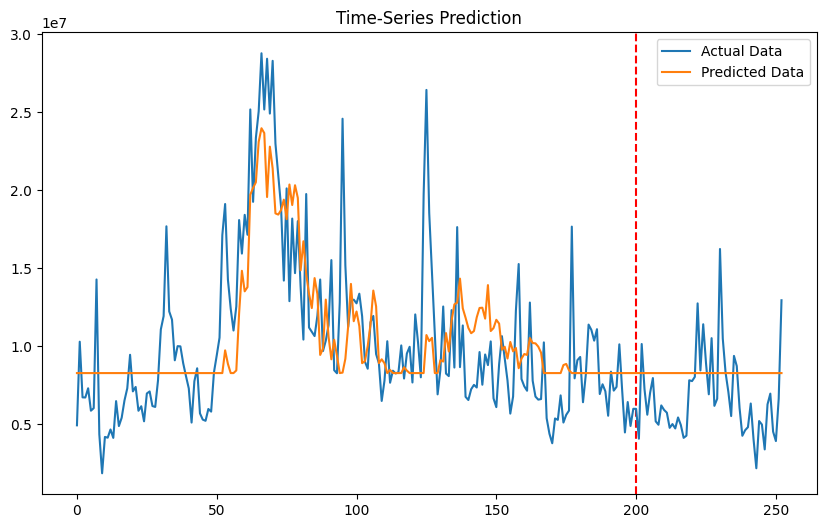

In [67]:
# 전체 데이터에 대한 예측 수행
train_predict = lstm_model(df_x_ss.to(device))

# CPU로 내려서 넘파이 배열로 변환
predicted = train_predict.cpu().data.numpy()
label_y = df_y_ms.data.numpy()

predicted = ms.inverse_transform(predicted)
label_y = ms.inverse_transform(label_y)

# 시각화
plt.figure(figsize=(10, 6))
plt.axvline(x=200, c='r', linestyle='--')  # 200번째 인덱스 기준선 (학습/테스트 경계)

plt.plot(label_y, label='Actual Data')
plt.plot(predicted, label='Predicted Data')
plt.title('Time-Series Prediction')
plt.legend()
plt.show()